In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.0)
COLORS = {"Normal": "#2a78d6", "Attack": "#eb6834", 0: "#2a78d6", 1: "#eb6834"}
FIG = "../figures/"

ct = pd.read_csv("../data/ctdapd_clean.csv", keep_default_na=False)
ci = pd.read_csv("../data/intrusion_clean.csv", keep_default_na=False)

ct_num = ["Flow_Duration", "Packet_Size", "Total_Forward_Packets",
          "Total_Backward_Packets", "IDS_Alert_Count", "Anomaly_Score"]
ct_cat = ["Destination_Port", "Protocol_Type", "System_Patch_Status"]
ci_num = ["network_packet_size", "login_attempts", "session_duration",
          "ip_reputation_score", "failed_logins"]
ci_cat = ["protocol_type", "encryption_used", "unusual_time_access"]
print(ct.shape, ci.shape)

(54768, 12) (9537, 9)


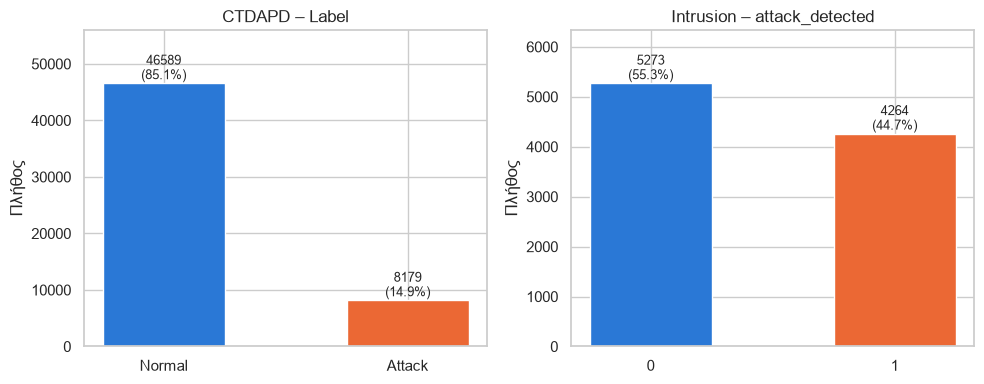

In [2]:
# ισοροπια κλασεων 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, df, col, title in [(axes[0], ct, "Label", "CTDAPD – Label"),
                           (axes[1], ci, "attack_detected", "Intrusion – attack_detected")]:
    counts = df[col].value_counts()
    bars = ax.bar(counts.index.astype(str), counts.values,
                  color=[COLORS[k] for k in counts.index], width=0.5)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width()/2, v, f"{v}\n({v/len(df):.1%})",
                ha="center", va="bottom", fontsize=9)
    ax.set_title(title); ax.set_ylabel("Πλήθος"); ax.margins(y=0.2)
plt.tight_layout(); plt.savefig(FIG + "01_class_balance.png", dpi=200); plt.show()

In [3]:
print(ct[ct_num].describe().T.round(2))
print(ci[ci_num].describe().T.round(2))

                          count    mean     std    min     25%     50%  \
Flow_Duration           54768.0   99.99  100.91   0.00   28.00   69.00   
Packet_Size             54768.0  499.51  149.59 -98.00  399.00  500.00   
Total_Forward_Packets   54768.0   20.03    4.49   5.00   17.00   20.00   
Total_Backward_Packets  54768.0   15.02    3.87   2.00   12.00   15.00   
IDS_Alert_Count         54768.0    1.00    1.00   0.00    0.00    1.00   
Anomaly_Score           54768.0   28.43   15.99   0.11   15.92   26.16   

                           75%      max  
Flow_Duration           138.00  1419.00  
Packet_Size             600.00  1178.00  
Total_Forward_Packets    23.00    48.00  
Total_Backward_Packets   18.00    34.00  
IDS_Alert_Count           2.00     8.00  
Anomaly_Score            38.68    93.56  
                      count    mean     std   min     25%     50%      75%  \
network_packet_size  9537.0  500.43  198.38  64.0  365.00  499.00   635.00   
login_attempts       9537.0    

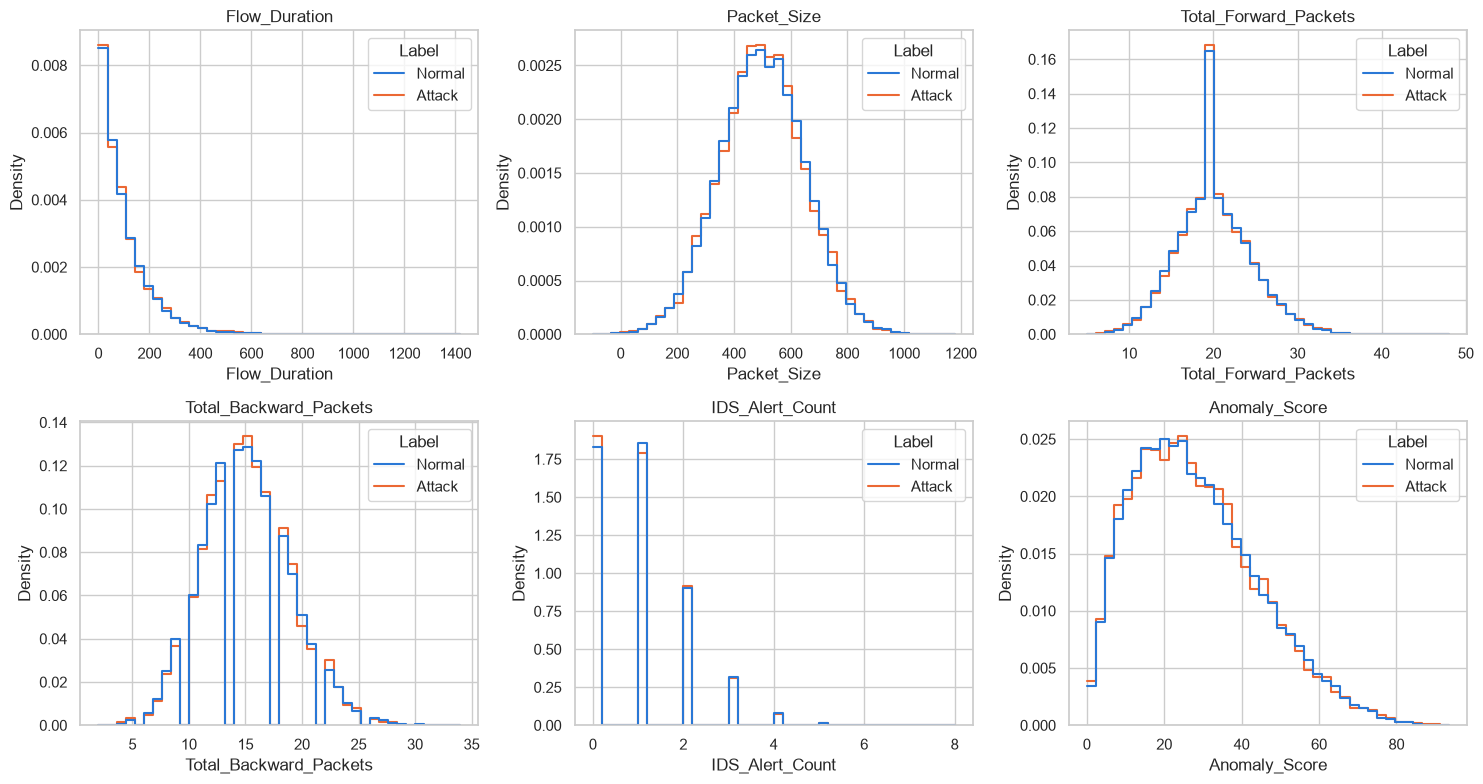

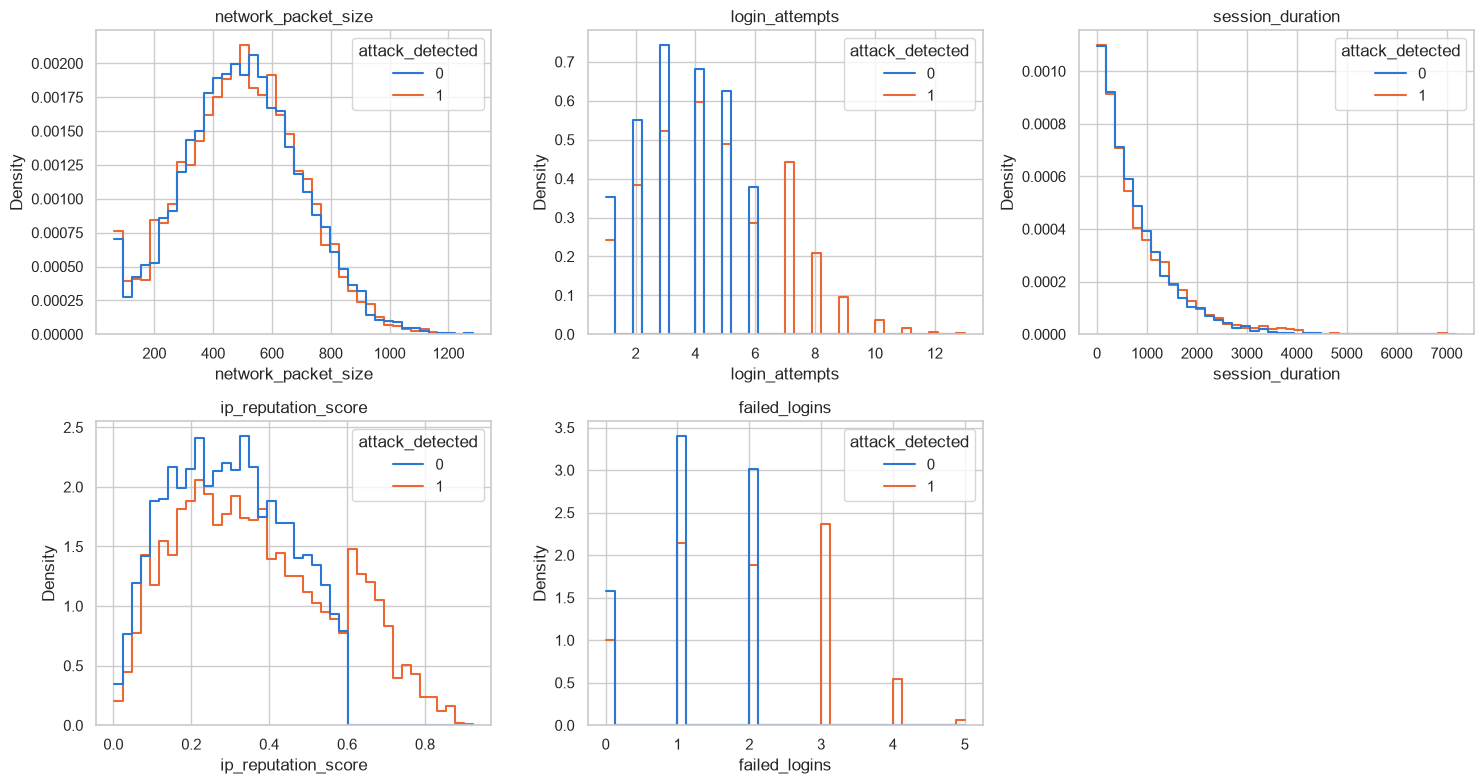

In [4]:
#κατανομες αριθμητικων χαρακτηριστικων ανα κλαση
def plot_numeric(df, cols, target, name):
    n = len(cols); fig, axes = plt.subplots(2, 3, figsize=(15, 8)); axes = axes.ravel()
    for ax, c in zip(axes, cols):
        sns.histplot(data=df, x=c, hue=target, palette=COLORS, stat="density",
                     common_norm=False, element="step", fill=False, bins=40, ax=ax)
        ax.set_title(c)
    for ax in axes[n:]: ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG + name, dpi=200); plt.show()

plot_numeric(ct, ct_num, "Label", "02_ctdapd_numeric.png")
plot_numeric(ci, ci_num, "attack_detected", "03_intrusion_numeric.png")

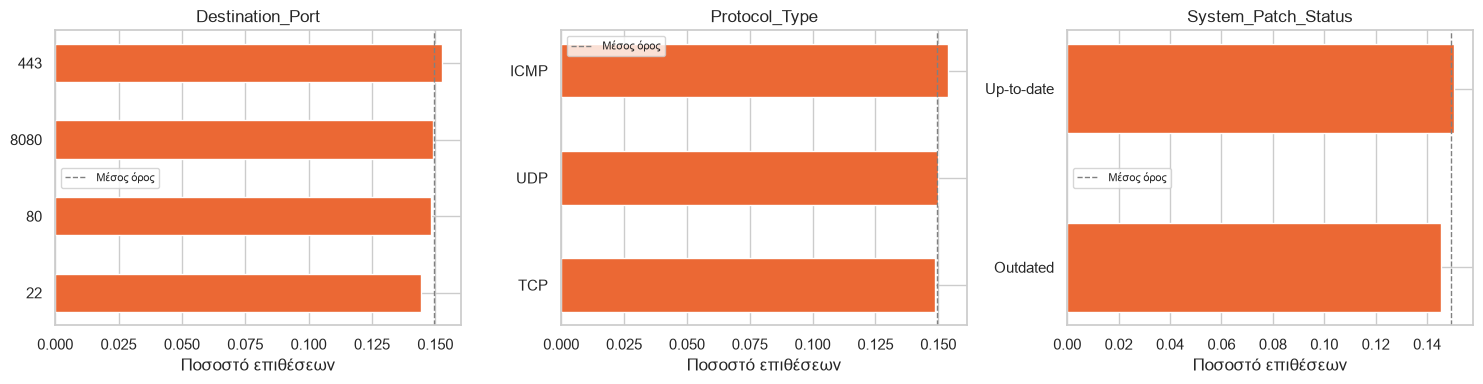

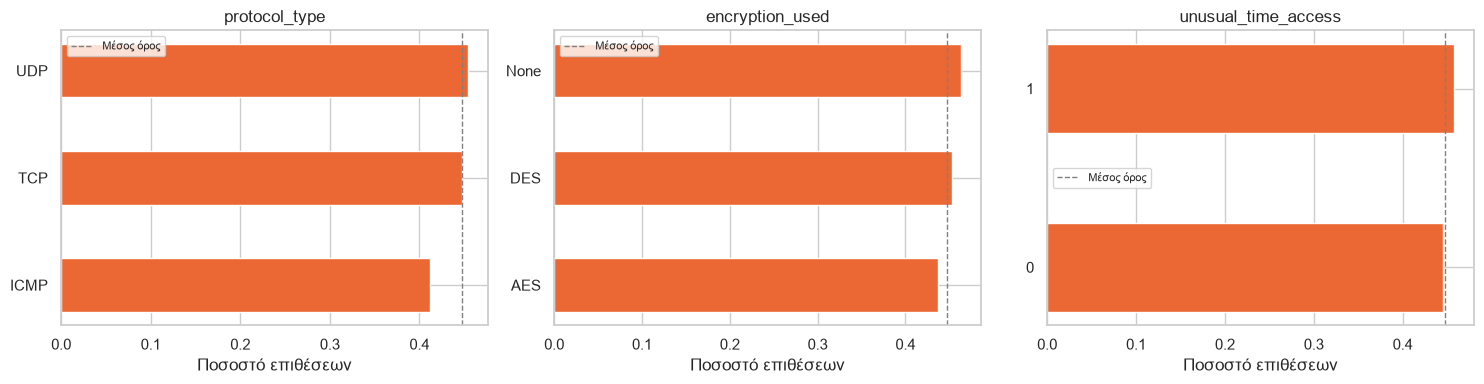

In [5]:
#επιθεσης ανα κατηγορια 
def attack_rate(df, cols, target, positive, name):
    fig, axes = plt.subplots(1, len(cols), figsize=(5*len(cols), 4))
    for ax, c in zip(axes, cols):
        rate = (df[target] == positive).groupby(df[c]).mean().sort_values()
        ax.barh(rate.index.astype(str), rate.values, color="#eb6834", height=0.5)
        ax.axvline((df[target] == positive).mean(), color="gray", ls="--", lw=1, label="Μέσος όρος")
        ax.set_title(c); ax.set_xlabel("Ποσοστό επιθέσεων"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(FIG + name, dpi=200); plt.show()

attack_rate(ct, ct_cat, "Label", "Attack", "04_ctdapd_categorical.png")
attack_rate(ci, ci_cat, "attack_detected", 1, "05_intrusion_categorical.png")

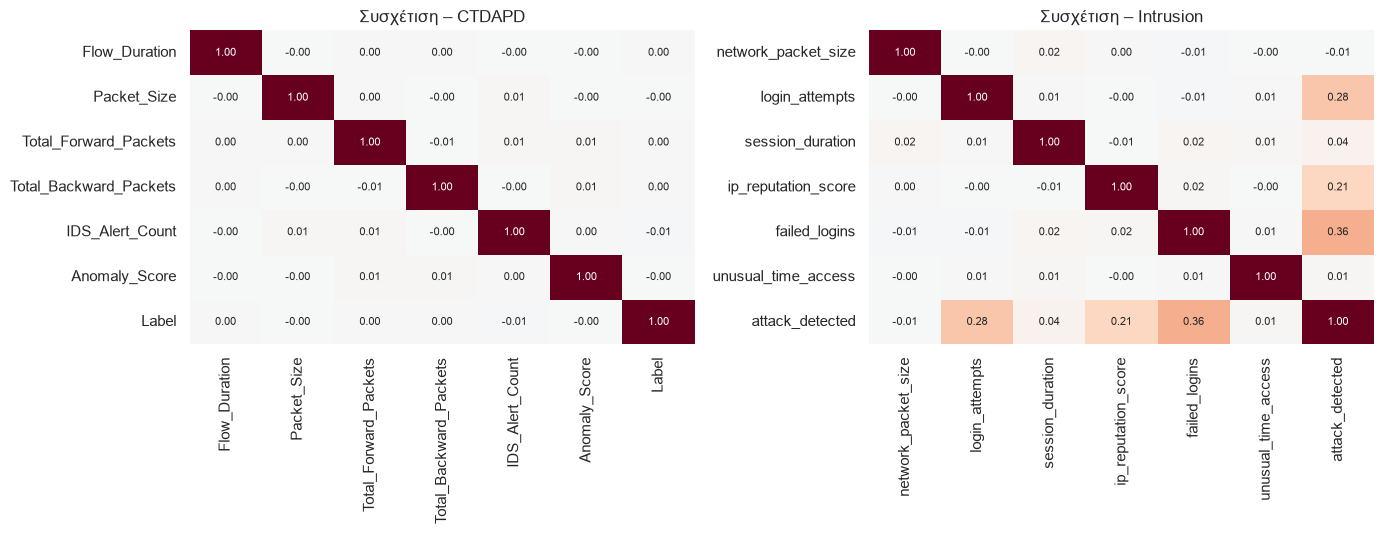

In [6]:
#πινακας συσχετισης 
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
c1 = ct[ct_num].assign(Label=(ct["Label"] == "Attack").astype(int)).corr()
c2 = ci[ci_num + ["unusual_time_access", "attack_detected"]].corr()
for ax, c, t in [(axes[0], c1, "CTDAPD"), (axes[1], c2, "Intrusion")]:
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                center=0, ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set_title(f"Συσχέτιση – {t}")
plt.tight_layout(); plt.savefig(FIG + "06_correlations.png", dpi=200); plt.show()

Attack_Vector  Brute Force  DDoS   None  SQL Injection
Label                                                 
Attack                 418   799   6538            424
Normal                2336  4682  37297           2274
Attack_Severity   High    Low  Medium
Label                                
Attack           0.096  0.613   0.291
Normal           0.098  0.601   0.301


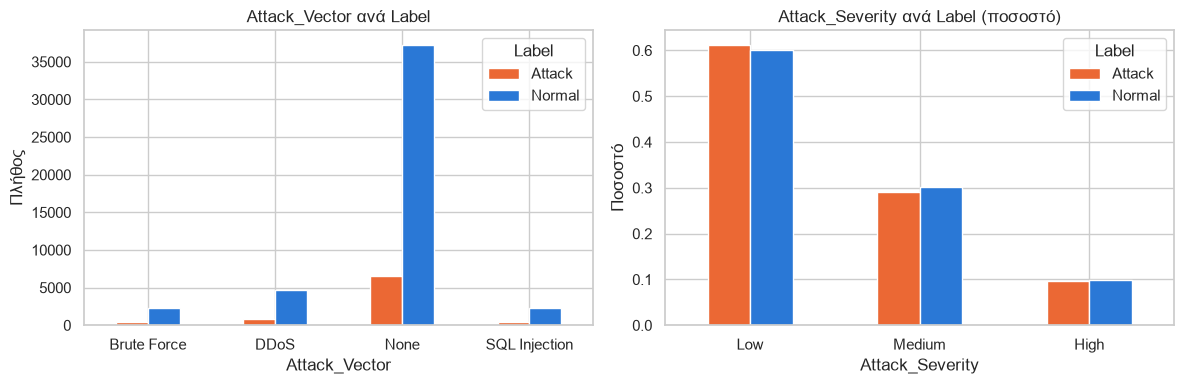

In [7]:
#σχεση attack vector και severity με label 
print(pd.crosstab(ct["Label"], ct["Attack_Vector"]))
print(pd.crosstab(ct["Label"], ct["Attack_Severity"], normalize="index").round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(ct["Attack_Vector"], ct["Label"]).plot(kind="bar", ax=axes[0], color=[COLORS["Attack"], COLORS["Normal"]], rot=0)
axes[0].set_title("Attack_Vector ανά Label"); axes[0].set_ylabel("Πλήθος")
pd.crosstab(ct["Attack_Severity"], ct["Label"], normalize="columns").loc[["Low","Medium","High"]].plot(
    kind="bar", ax=axes[1], color=[COLORS["Attack"], COLORS["Normal"]], rot=0)
axes[1].set_title("Attack_Severity ανά Label (ποσοστό)"); axes[1].set_ylabel("Ποσοστό")
plt.tight_layout(); plt.savefig(FIG + "07_ctdapd_targets.png", dpi=200); plt.show()

In [8]:
#ελεγχος προβλεψιμοτητας 
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score

def quick_auc(df, feats, y):
    X = df[feats].copy()
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype("category").cat.codes
    m = HistGradientBoostingClassifier(max_iter=200, random_state=42)
    return cross_val_score(m, X, y, cv=5, scoring="roc_auc").mean()

print("CTDAPD    ROC-AUC:", round(quick_auc(ct, ct_num + ct_cat, (ct["Label"] == "Attack").astype(int)), 3))
print("Intrusion ROC-AUC:", round(quick_auc(ci, ci_num + ci_cat, ci["attack_detected"]), 3))

CTDAPD    ROC-AUC: 0.51
Intrusion ROC-AUC: 0.865
